# House-Price Estimator with Prediction Intervals
**Applied ML Lab (CSE2512P), Group 7 - Iconics, Track 4 (Functional MVP)**

This notebook covers the modelling part: data exploration and cleaning, a 60/20/20 train/calibration/test split,
a comparison of three regressors, and 90% prediction intervals using split conformal prediction.
The final model and interval width are saved for the FastAPI app (`python -m src.train` produces the same artefacts).

**Dataset:** California Housing (Pace & Barry, 1997), loaded via scikit-learn. Target is median house value in units of $100,000.

In [36]:
import sys; 
print(sys.executable)
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

from src.data import load_clean_data, PRICE_CAP, MAX_AVE_ROOMS, MAX_AVE_BEDRMS, MAX_AVE_OCCUP, MAX_POPULATION
from src.intervals import conformal_quantile, coverage

SEED = 42
ALPHA = 0.10  # 90% prediction intervals
plt.rcParams["figure.figsize"] = (7, 4)
FIG = ROOT / "report" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

/Users/aryanpahal/house-price-estimator/.venv/bin/python3.14


## 1. Load raw data and explore

In [20]:
raw = fetch_california_housing(as_frame=True)
X_raw, y_raw = raw.data, raw.target
df = X_raw.assign(MedHouseVal=y_raw)
print(df.shape)
df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [21]:
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(X_raw.duplicated().sum()))
df.describe().T

Missing values: 0
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


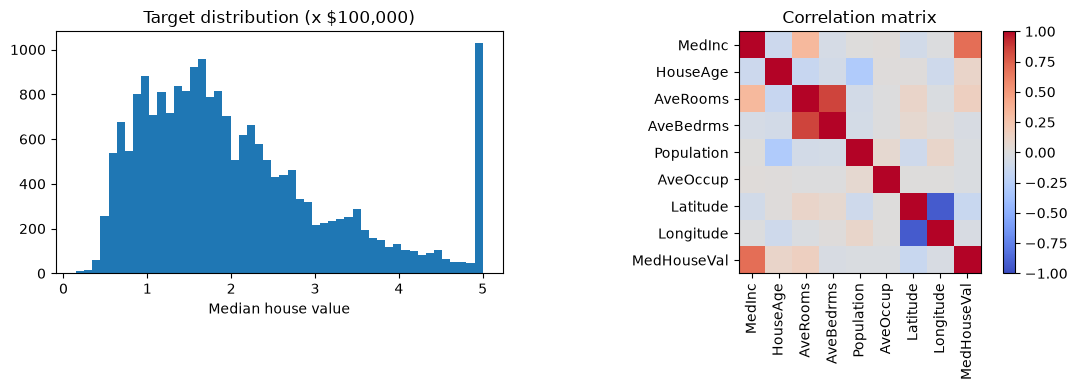

In [37]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(y_raw, bins=50)
ax[0].set_title("Target distribution (x $100,000)")
ax[0].set_xlabel("Median house value")
corr = df.corr()
im = ax[1].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax[1].set_xticks(range(len(corr)), corr.columns, rotation=90)
ax[1].set_yticks(range(len(corr)), corr.columns)
ax[1].set_title("Correlation matrix")
fig.colorbar(im, ax=ax[1])
plt.tight_layout(); 
fig.savefig(FIG / "fig1_eda.png", dpi=200, bbox_inches="tight")
plt.show()

The spike at 5.0 is the price cap: every house worth more than $500k is recorded as exactly 5.0, so the model cannot learn their real value.

## 2. Data cleaning
Rules are fixed domain thresholds (defined in `src/data.py`), so applying them before the split does not leak information from test into train.

In [23]:
rules = {
    f"Price at cap (>= {PRICE_CAP})": y_raw >= PRICE_CAP,
    f"AveRooms > {MAX_AVE_ROOMS}": X_raw["AveRooms"] > MAX_AVE_ROOMS,
    f"AveBedrms > {MAX_AVE_BEDRMS}": X_raw["AveBedrms"] > MAX_AVE_BEDRMS,
    f"AveOccup > {MAX_AVE_OCCUP}": X_raw["AveOccup"] > MAX_AVE_OCCUP,
    f"Population > {MAX_POPULATION}": X_raw["Population"] > MAX_POPULATION,
}
cleaning_table = pd.DataFrame({"rows_flagged": {k: int(v.sum()) for k, v in rules.items()}})
cleaning_table["share_%"] = (cleaning_table["rows_flagged"] / len(X_raw) * 100).round(2)
cleaning_table

,rows_flagged,share_%
Price at cap (>= 5.0),992,4.81
AveRooms > 20,69,0.33
AveBedrms > 5,45,0.22
AveOccup > 10,37,0.18
Population > 10000,23,0.11


In [24]:
X, y = load_clean_data()
print(X.describe().T[["min", "max"]])

Rows: 20640 -> 19522 (duplicates removed: 0, capped/outlier rows removed: 1118)
                   min          max
MedInc        0.499900    15.000100
HouseAge      1.000000    52.000000
AveRooms      0.846154    19.860000
AveBedrms     0.333333     4.980769
Population    3.000000  9936.000000
AveOccup      0.750000     9.954545
Latitude     32.540000    41.950000
Longitude  -124.350000  -114.310000


## 3. Split: 60% train / 20% calibration / 20% test
The calibration set is used only to size the prediction interval, and the test set is touched only for final evaluation.

In [25]:
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
X_train, X_cal, y_train, y_cal = train_test_split(X_tmp, y_tmp, test_size=0.25, random_state=SEED)
print(len(X_train), len(X_cal), len(X_test))

11712 3905 3905


## 4. Train and compare models

In [26]:
models = {
    "LinearRegression": LinearRegression(),
    "RandomForest": RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=SEED),
    "GradientBoosting": HistGradientBoostingRegressor(random_state=SEED),
}
rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    rows.append({
        "model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, p)),
        "MAE": mean_absolute_error(y_test, p),
        "R2": r2_score(y_test, p),
    })
results = pd.DataFrame(rows).set_index("model").round(4)
results

,RMSE,MAE,R2
model,,,
LinearRegression,0.6014,0.4473,0.6202
RandomForest,0.4739,0.3162,0.7641
GradientBoosting,0.4398,0.2998,0.7969


Gradient Boosting is used as the final model if it has the lowest RMSE/MAE in the table above.

## 5. Final model: predicted vs actual and feature importance

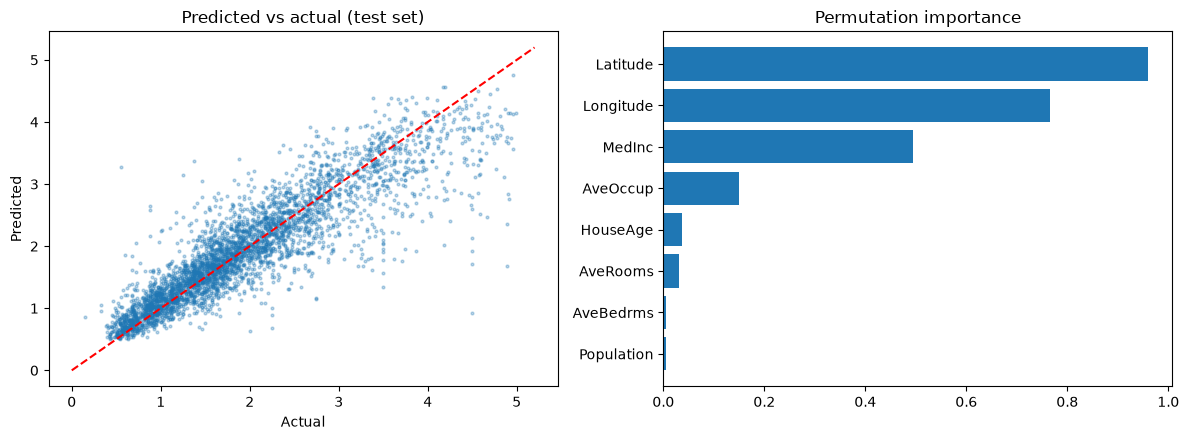

In [38]:
final = models["GradientBoosting"]
test_pred = final.predict(X_test)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(y_test, test_pred, s=4, alpha=0.3)
lims = [0, 5.2]
ax[0].plot(lims, lims, "r--")
ax[0].set_xlabel("Actual"); ax[0].set_ylabel("Predicted"); ax[0].set_title("Predicted vs actual (test set)")

imp = permutation_importance(final, X_test, y_test, n_repeats=5, random_state=SEED, n_jobs=-1)
order = np.argsort(imp.importances_mean)
ax[1].barh(X.columns[order], imp.importances_mean[order])
ax[1].set_title("Permutation importance")
plt.tight_layout(); 
fig.savefig(FIG / "fig2_pred_vs_actual.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Prediction intervals (split conformal)
The interval is `prediction +/- q`, where `q` is the 90th-percentile absolute error on the calibration set.

In [28]:
q = conformal_quantile(y_cal, final.predict(X_cal), alpha=ALPHA)
lower = np.clip(test_pred - q, 0, None)
upper = test_pred + q
emp_cov = coverage(y_test, lower, upper)
print(f"q (half-width) = {q:.4f}  (about ${q * 100_000:,.0f})")
print(f"Target coverage = {1 - ALPHA:.2f}, empirical test coverage = {emp_cov:.3f}")
print(f"Mean interval width = {np.mean(upper - lower):.3f}")

q (half-width) = 0.6579  (about $65,795)
Target coverage = 0.90, empirical test coverage = 0.899
Mean interval width = 1.314


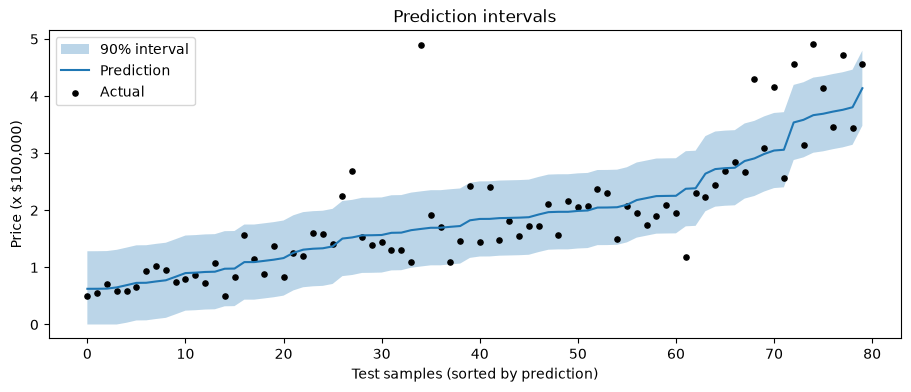

In [39]:
idx = np.random.RandomState(SEED).choice(len(y_test), 80, replace=False)
idx = idx[np.argsort(test_pred[idx])]
plt.figure(figsize=(11, 4))
plt.fill_between(range(len(idx)), lower[idx], upper[idx], alpha=0.3, label="90% interval")
plt.plot(test_pred[idx], label="Prediction")
plt.scatter(range(len(idx)), np.asarray(y_test)[idx], s=14, color="k", label="Actual")
plt.xlabel("Test samples (sorted by prediction)"); plt.ylabel("Price (x $100,000)")
plt.legend(); plt.title("Prediction intervals"); 
plt.savefig(FIG / "fig3_intervals.png", dpi=200, bbox_inches="tight")
plt.show()

### Coverage by price range
The interval has constant width, so coverage can differ between cheap and expensive houses. This is a limitation to discuss in the report.

In [30]:
bins = pd.cut(y_test, [0, 1.5, 2.5, 3.5, 5.1])
by_bin = pd.DataFrame({"bin": bins, "hit": (y_test >= lower) & (y_test <= upper)}).groupby("bin", observed=True)["hit"].agg(["mean", "count"])
by_bin.columns = ["coverage", "n"]
by_bin.round(3)

,coverage,n
bin,,
"(0.0, 1.5]",0.962,1494
"(1.5, 2.5]",0.930,1461
"(2.5, 3.5]",0.821,625
"(3.5, 5.1]",0.615,325


## 7. Save artefacts for the API

In [31]:
import json, joblib
(ROOT / "models").mkdir(exist_ok=True)
(ROOT / "report").mkdir(exist_ok=True)
joblib.dump({"model": final, "q": q, "features": list(X.columns), "confidence": 1 - ALPHA},
            ROOT / "models" / "model.joblib")
summary = {"cleaning": cleaning_table.to_dict(orient="index"),
           "point_models": results.to_dict(orient="index"),
           "intervals": {"target_coverage": 1 - ALPHA, "empirical_coverage_on_test": emp_cov,
                         "half_width_q": q, "mean_interval_width": float(np.mean(upper - lower))}}
(ROOT / "report" / "metrics.json").write_text(json.dumps(summary, indent=2))
print("Saved models/model.joblib and report/metrics.json")

Saved models/model.joblib and report/metrics.json


## 8. Sanity check: the same predictor the API uses

In [32]:
from app.predictor import predict_with_interval
sample = {"MedInc": 3.5, "HouseAge": 20, "AveRooms": 5.0, "AveBedrms": 1.0,
          "Population": 1200, "AveOccup": 3.0, "Latitude": 34.0, "Longitude": -118.0}
pred, lo, hi = predict_with_interval(sample)
print(f"Predicted ${pred * 100_000:,.0f}  (90% range ${lo * 100_000:,.0f} - ${hi * 100_000:,.0f})")

Predicted $194,634  (90% range $128,839 - $260,429)


## References
- Pace, R. K. and Barry, R. (1997). Sparse spatial autoregressions. *Statistics & Probability Letters*, 33(3).
- Pedregosa et al. (2011). Scikit-learn: Machine Learning in Python. *JMLR*, 12.
- Vovk, Gammerman, Shafer (2005). *Algorithmic Learning in a Random World* (conformal prediction).
- Lei et al. (2018). Distribution-free predictive inference for regression. *JASA*, 113(523).